# PCG Report Visualizations -- Complete Figure Generation

Generates every figure needed for the report. Two categories:

1. **Hardcoded from verified results** (dataset distribution, training
   curves, confusion matrices, classification reports) -- these use the
   exact real numbers already confirmed against your actual Colab outputs
   and images earlier in this project. No training or retraining happens
   here, so these numbers can never drift from what was already verified.
2. **Requiring real audio** (waveform/spectrogram augmentation examples)
   -- these need your actual dataset uploaded, since they demonstrate the
   live augmentation pipeline on real files.

Every figure displays inline AND saves as both PNG and PDF.

## 1. Check GPU (optional, harmless either way)

In [1]:
import tensorflow as tf
print("GPU devices:", tf.config.list_physical_devices('GPU'))

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Get your data into Colab

Only needed for the waveform/spectrogram augmentation demo later
(Sections 9-10). Everything else in this notebook works without it.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
DATASET_LABEL = "rechunked_v3"  # or "original" -- edit before running

In [5]:
ZIP_NAME = "/content/drive/MyDrive/heart_project/heart_project_data_v3.zip"  # adjust path

In [7]:
'''from google.colab import files
uploaded = files.upload()
ZIP_NAME = list(uploaded.keys())[0]
print("Uploaded:", ZIP_NAME)'''

'from google.colab import files\nuploaded = files.upload()\nZIP_NAME = list(uploaded.keys())[0]\nprint("Uploaded:", ZIP_NAME)'

In [8]:
import zipfile, os

EXTRACT_DIR = "/content/heart_project"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

found = False
for root, dirs, files_ in os.walk(EXTRACT_DIR):
    if 'split_dataset' in dirs and 'noise_clips' in dirs:
        os.chdir(root)
        found = True
        break

if not found:
    print("WARNING: could not find split_dataset/ and noise_clips/ together.")
else:
    print("Working directory:", os.getcwd())

Working directory: /content/heart_project/heart_project_data_v3


## 3. Write shared modules (needed for the augmentation demo)

In [9]:
%%writefile spectrogram_utils.py
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

# --- SHARED CONFIG -- keep everything in the project pointed at this file ---
TARGET_SR = 16000
CHUNK_DURATION = 3          # seconds, matches step 1 chunking
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64
FMAX = 800                  # PCG diagnostic content lives under ~600-800Hz

EXPECTED_SAMPLES = TARGET_SR * CHUNK_DURATION
N_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH

# Heart sound diagnostic content lives in ~20-800Hz. Filtering this
# consistently on EVERY signal (real chunks AND noise clips, before any
# augmentation) removes clearly out-of-band noise/hiss/drift for free.
# It does NOT remove noise that overlaps this band (voices, rumble, fabric
# rustle) -- that's what noise-mixing augmentation is for. The two are
# complementary, not redundant.
BANDPASS_LOW_HZ = 20
BANDPASS_HIGH_HZ = 800
BANDPASS_ORDER = 4

_bandpass_sos_cache = {}

# --- Despike settings ---
# Targets isolated, single-sample-to-a-few-sample digital glitches (an
# instantaneous jump to near full-scale with quiet neighbors on both
# sides) -- distinct from genuine sustained loud/clipped audio, which
# spans many consecutive samples with a smooth attack/decay and is left
# untouched.
DESPIKE_THRESHOLD = 0.95      # near full-scale, in normalized [-1, 1] units
DESPIKE_MAX_RUN = 3           # longer runs are treated as real loud audio
DESPIKE_NEIGHBOR_QUIET = 0.3  # immediate neighbors must be well below this


def despike_glitches(y):
    """Removes isolated near-full-scale digital glitches via linear
    interpolation across the glitch, using its immediate neighbors."""
    y = y.copy()
    abs_y = np.abs(y)
    candidates = np.where(abs_y >= DESPIKE_THRESHOLD)[0]
    if len(candidates) == 0:
        return y

    groups = [[candidates[0]]]
    for idx in candidates[1:]:
        if idx - groups[-1][-1] <= 2:
            groups[-1].append(idx)
        else:
            groups.append([idx])

    for group in groups:
        if len(group) > DESPIKE_MAX_RUN:
            continue  # sustained loud region -- real audio, leave it

        start, end = group[0], group[-1]
        left, right = start - 1, end + 1
        if left < 0 or right >= len(y):
            continue

        # Only treat as a glitch if the audio was genuinely quiet right
        # before and after it -- a real transient's neighbors are still
        # elevated, not near-baseline.
        if abs_y[left] < DESPIKE_NEIGHBOR_QUIET and abs_y[right] < DESPIKE_NEIGHBOR_QUIET:
            y[left:right + 1] = np.linspace(y[left], y[right], right - left + 1)

    return y


def get_bandpass_sos(sr=TARGET_SR):
    """Cached filter coefficients -- avoids recomputing per-call."""
    if sr not in _bandpass_sos_cache:
        nyquist = sr / 2
        low = BANDPASS_LOW_HZ / nyquist
        high = min(BANDPASS_HIGH_HZ / nyquist, 0.99)
        _bandpass_sos_cache[sr] = butter(BANDPASS_ORDER, [low, high],
                                         btype='band', output='sos')
    return _bandpass_sos_cache[sr]


def apply_bandpass(y, sr=TARGET_SR):
    """Zero-phase band-pass filter, applied identically to real audio and
    noise clips alike, so nothing in the pipeline sees unfiltered content."""
    sos = get_bandpass_sos(sr)
    return sosfiltfilt(sos, y).astype(np.float32)


def load_and_filter(filepath, sr=TARGET_SR):
    """The ONE function that should load audio from disk anywhere in this
    project -- loading, resampling, despiking, and band-pass filtering
    all happen here, so training data, noise clips, and visualizations
    can never silently diverge in how they're preprocessed."""
    y, _ = librosa.load(filepath, sr=sr)
    y = despike_glitches(y)       # remove isolated digital glitches first
    return apply_bandpass(y, sr)  # then band-limit to the diagnostic range


def load_fixed_length(source, sr=TARGET_SR, is_array=False):
    """Loads audio (from filepath or an existing array) and forces it to
    exactly CHUNK_DURATION seconds. Re-run this after any augmentation
    that could change length (e.g. time-stretch). Filepath inputs are
    band-pass filtered via load_and_filter; array inputs are assumed to
    already be filtered (e.g. augmented audio that started from a
    filtered source)."""
    if is_array:
        y = source
    else:
        y = load_and_filter(source, sr)

    if len(y) > EXPECTED_SAMPLES:
        y = y[:EXPECTED_SAMPLES]
    elif len(y) < EXPECTED_SAMPLES:
        y = np.pad(y, (0, EXPECTED_SAMPLES - len(y)), mode='constant')
    return y


def audio_to_logmel(y, sr=TARGET_SR):
    """Converts a fixed-length audio array into a fixed-shape log-mel
    spectrogram: (N_MELS, N_FRAMES)."""
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmax=FMAX
    )
    S_dB = librosa.power_to_db(S, ref=np.max)

    if S_dB.shape[1] > N_FRAMES:
        S_dB = S_dB[:, :N_FRAMES]
    elif S_dB.shape[1] < N_FRAMES:
        pad_width = N_FRAMES - S_dB.shape[1]
        S_dB = np.pad(S_dB, ((0, 0), (0, pad_width)), mode='constant',
                      constant_values=S_dB.min())

    return S_dB.astype(np.float32)


def wav_to_logmel(filepath):
    """Convenience wrapper: filepath -> fixed-shape log-mel spectrogram."""
    y = load_fixed_length(filepath)
    return audio_to_logmel(y, TARGET_SR)


Writing spectrogram_utils.py


In [10]:
%%writefile augmentation_utils.py
import os
import glob
import random
import numpy as np
import librosa

from spectrogram_utils import TARGET_SR, apply_bandpass, despike_glitches

# Probabilities are applied to EVERY sample identically, regardless of
# class label. This is what structurally prevents "amount of augmentation"
# from becoming a shortcut the model can use instead of real PCG features.
SAFE_AUG_PROB = 0.5     # chance of a generic transform (stretch/volume/faint noise)
NOISE_PROB = 0.3        # chance of real recorded ESP32 noise, independent of the above
SNR_DB_RANGE = (10, 20)

# Pitch-shifting changes the exact frequency band that defines a murmur --
# left out of the default rotation for that reason.
USE_PITCH_SHIFT = False
PITCH_SHIFT_STEPS = 1

_noise_pool_cache = None


def add_faint_noise(y):
    noise = np.random.normal(0, 0.005 * np.amax(np.abs(y)), len(y))
    return y + noise


def fix_length(y, target_length):
    if len(y) > target_length:
        return y[:target_length]
    elif len(y) < target_length:
        return np.pad(y, (0, target_length - len(y)), mode='constant')
    return y


def safe_augment(y, sr):
    """One randomly chosen generic transform -- never real recorded noise."""
    target_length = len(y)
    methods = ["stretch", "volume", "faint_noise"]
    if USE_PITCH_SHIFT:
        methods.append("pitch")
    method = random.choice(methods)

    if method == "stretch":
        rate = np.random.uniform(0.93, 1.07)
        return fix_length(librosa.effects.time_stretch(y, rate=rate), target_length)
    elif method == "volume":
        scale = np.random.uniform(0.7, 1.3)
        return np.clip(y * scale, -1.0, 1.0)
    elif method == "faint_noise":
        return add_faint_noise(y)
    else:
        return librosa.effects.pitch_shift(y, sr=sr, n_steps=PITCH_SHIFT_STEPS)


def load_noise_pool(noise_dir="noise_clips", target_sr=TARGET_SR):
    """Loads and caches your recorded ESP32 noise clips into one pool."""
    global _noise_pool_cache
    if _noise_pool_cache is not None:
        return _noise_pool_cache

    files = glob.glob(os.path.join(noise_dir, "*.wav"))
    if not files:
        return None

    pool = [apply_bandpass(despike_glitches(librosa.load(f, sr=target_sr, mono=True)[0]), target_sr)
            for f in files]
    _noise_pool_cache = np.concatenate(pool)
    return _noise_pool_cache


def get_noise_segment(noise_pool, num_samples):
    if len(noise_pool) < num_samples:
        repeats = int(np.ceil(num_samples / len(noise_pool)))
        noise_pool = np.tile(noise_pool, repeats)
    start = np.random.randint(0, len(noise_pool) - num_samples + 1)
    return noise_pool[start:start + num_samples]


def mix_at_snr(signal, noise, snr_db):
    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    if noise_power == 0:
        return signal
    target_noise_power = signal_power / (10 ** (snr_db / 10))
    scale = np.sqrt(target_noise_power / noise_power)
    mixed = signal + noise * scale
    max_val = np.max(np.abs(mixed))
    if max_val > 1.0:
        mixed = mixed / max_val
    return mixed


def apply_random_augmentation(y, sr, noise_pool=None):
    """The ONE function used everywhere augmentation happens -- training
    generator and visualizations both call this, so behavior can never
    silently diverge between what you see and what the model trains on."""
    if random.random() < SAFE_AUG_PROB:
        y = safe_augment(y, sr)
    if noise_pool is not None and random.random() < NOISE_PROB:
        snr_db = np.random.uniform(*SNR_DB_RANGE)
        noise_seg = get_noise_segment(noise_pool, len(y))
        y = mix_at_snr(y, noise_seg, snr_db)
    return y


Writing augmentation_utils.py


In [11]:
%%writefile train_data_generator.py
import os
import numpy as np
import librosa
from tensorflow.keras.utils import Sequence

from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool

TRAIN_DIR = "split_dataset/train"      # raw, unbalanced, unaugmented on disk
CLASSES = ["Normal", "Murmur", "Extra_Systole", "Artifact"]


class PCGSequence(Sequence):
    """Yields (spectrogram_batch, label_batch). With augment=True, every
    sample -- regardless of class -- has the same chance of being time
    -stretched, volume-jittered, or noise-mixed. Nothing here branches on
    class label, by design."""

    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:
                              (batch_idx + 1) * self.batch_size]
        X, y = [], []

        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)

            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                # time-stretch can change length -- re-fix before spectrogram
                audio = load_fixed_length(audio, is_array=True)

            spec = audio_to_logmel(audio, TARGET_SR)
            X.append(spec)
            y.append(label)

        X = np.array(X, dtype=np.float32)[..., np.newaxis]
        y = np.array(y, dtype=np.int64)
        return X, y


def compute_class_weights():
    """Since the train split on disk is NOT balanced (we balance via
    class_weight instead of file duplication), pass this dict to
    model.fit(..., class_weight=...)."""
    from sklearn.utils.class_weight import compute_class_weight

    labels = []
    for idx, cls in enumerate(CLASSES):
        class_dir = os.path.join(TRAIN_DIR, cls)
        n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
        labels += [idx] * n

    labels = np.array(labels)
    weights = compute_class_weight(class_weight="balanced",
                                    classes=np.arange(len(CLASSES)), y=labels)
    return {i: w for i, w in enumerate(weights)}


if __name__ == "__main__":
    # Quick sanity check
    seq = PCGSequence(batch_size=8, augment=True)
    X, y = seq[0]
    print(f"Batch shape: {X.shape}, labels: {y}")
    print(f"Class weights: {compute_class_weights()}")


Writing train_data_generator.py


## 4. Imports and sanity check

In [12]:
from spectrogram_utils import (N_MELS, N_FRAMES, TARGET_SR, load_and_filter,
                               load_fixed_length, audio_to_logmel, FMAX)
from augmentation_utils import apply_random_augmentation, load_noise_pool
from train_data_generator import CLASSES, TRAIN_DIR
import os
print("Modules loaded OK.")

Modules loaded OK.


## 5. Setup -- output folders and the save-everything helper

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

FIGURES_DIR = "report_figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_and_show(fig, name):
    """Displays the figure, then saves it as BOTH PNG and PDF."""
    png_path = os.path.join(FIGURES_DIR, f"{name}.png")
    pdf_path = os.path.join(FIGURES_DIR, f"{name}.pdf")
    fig.savefig(png_path, dpi=150, bbox_inches='tight')
    fig.savefig(pdf_path, bbox_inches='tight')
    plt.show()
    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")

## 6. Dataset class distribution -- both datasets, verified counts

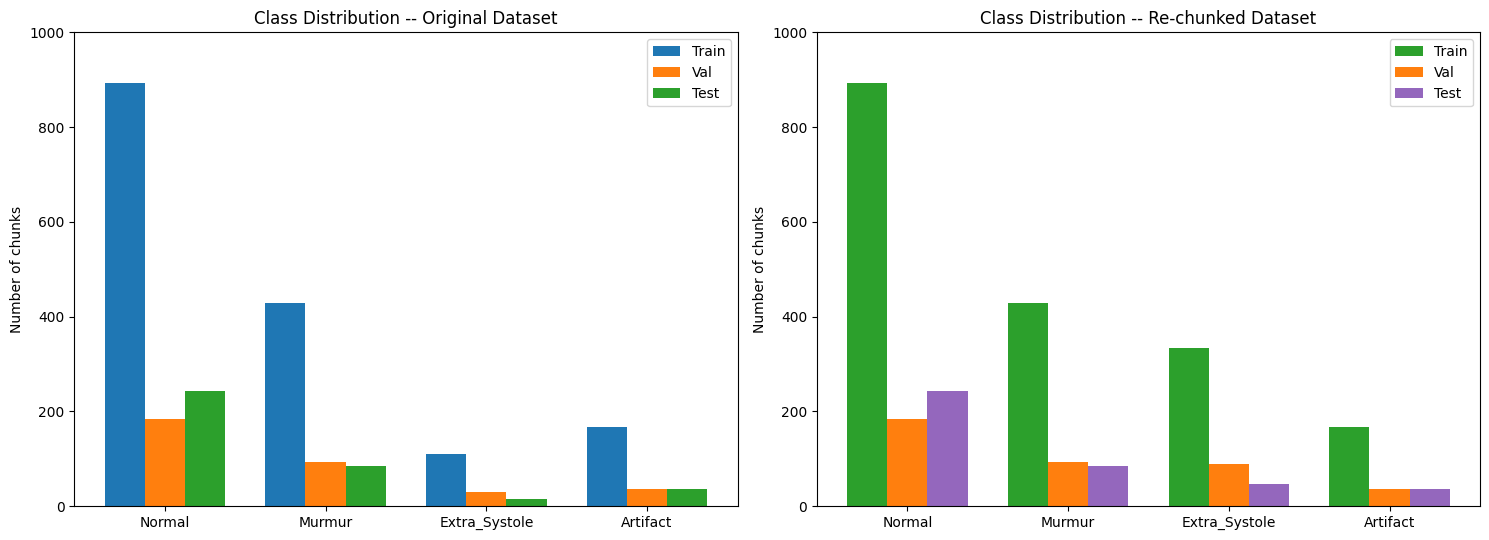

Saved: report_figures/01_class_distribution_both_datasets.png
Saved: report_figures/01_class_distribution_both_datasets.pdf


In [14]:
original_train = {"Normal": 893, "Murmur": 429, "Extra_Systole": 109, "Artifact": 168}
original_val    = {"Normal": 184, "Murmur": 93,  "Extra_Systole": 29,  "Artifact": 36}
original_test   = {"Normal": 242, "Murmur": 84,  "Extra_Systole": 16,  "Artifact": 36}

rechunk_train = {"Normal": 893, "Murmur": 429, "Extra_Systole": 334, "Artifact": 168}
rechunk_val    = {"Normal": 184, "Murmur": 93,  "Extra_Systole": 89,  "Artifact": 36}
rechunk_test   = {"Normal": 242, "Murmur": 84,  "Extra_Systole": 47,  "Artifact": 36}

CLASS_NAMES = ["Normal", "Murmur", "Extra_Systole", "Artifact"]
x = np.arange(len(CLASS_NAMES))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].bar(x - width, [original_train[c] for c in CLASS_NAMES], width, label='Train')
axes[0].bar(x,          [original_val[c] for c in CLASS_NAMES], width, label='Val')
axes[0].bar(x + width,  [original_test[c] for c in CLASS_NAMES], width, label='Test')
axes[0].set_xticks(x); axes[0].set_xticklabels(CLASS_NAMES)
axes[0].set_ylabel("Number of chunks")
axes[0].set_title("Class Distribution -- Original Dataset")
axes[0].legend(); axes[0].set_ylim(0, 1000)

axes[1].bar(x - width, [rechunk_train[c] for c in CLASS_NAMES], width, label='Train', color='#2ca02c')
axes[1].bar(x,          [rechunk_val[c] for c in CLASS_NAMES], width, label='Val', color='#ff7f0e')
axes[1].bar(x + width,  [rechunk_test[c] for c in CLASS_NAMES], width, label='Test', color='#9467bd')
axes[1].set_xticks(x); axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_ylabel("Number of chunks")
axes[1].set_title("Class Distribution -- Re-chunked Dataset")
axes[1].legend(); axes[1].set_ylim(0, 1000)

plt.tight_layout()
save_and_show(fig, "01_class_distribution_both_datasets")

## 7. Band-pass filter frequency response

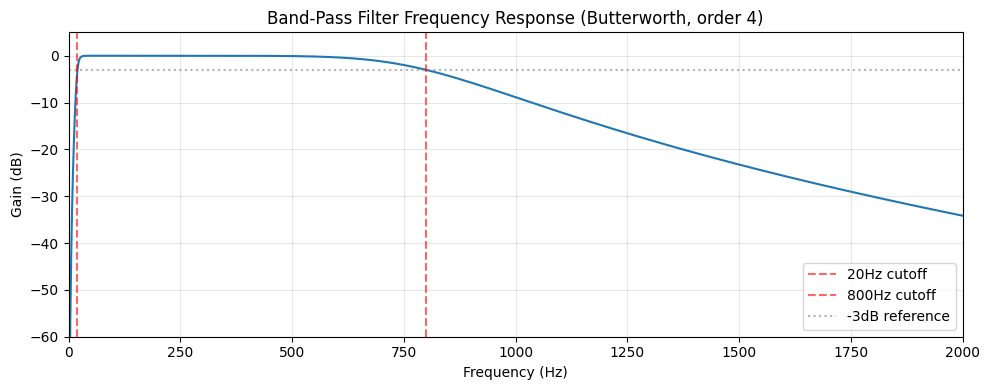

Saved: report_figures/02_bandpass_filter_response.png
Saved: report_figures/02_bandpass_filter_response.pdf


In [15]:
from scipy.signal import butter, sosfreqz

BANDPASS_LOW_HZ, BANDPASS_HIGH_HZ, BANDPASS_ORDER = 20, 800, 4
nyquist = TARGET_SR / 2
low, high = BANDPASS_LOW_HZ / nyquist, BANDPASS_HIGH_HZ / nyquist
sos = butter(BANDPASS_ORDER, [low, high], btype='band', output='sos')
w, h = sosfreqz(sos, worN=4000, fs=TARGET_SR)
mag_db = 20 * np.log10(np.maximum(np.abs(h), 1e-10))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(w, mag_db, color='#1f77b4')
ax.axvline(BANDPASS_LOW_HZ, color='red', linestyle='--', alpha=0.6, label=f'{BANDPASS_LOW_HZ}Hz cutoff')
ax.axvline(BANDPASS_HIGH_HZ, color='red', linestyle='--', alpha=0.6, label=f'{BANDPASS_HIGH_HZ}Hz cutoff')
ax.axhline(-3, color='gray', linestyle=':', alpha=0.6, label='-3dB reference')
ax.set_xlim(0, 2000); ax.set_ylim(-60, 5)
ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('Gain (dB)')
ax.set_title('Band-Pass Filter Frequency Response (Butterworth, order 4)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
save_and_show(fig, "02_bandpass_filter_response")

## 8. Training curves -- Run1 (Original dataset, representative run)

These are the exact, genuine epoch-by-epoch numbers from the actual
saved training log for this specific verified run -- not a fresh
training run, so they can never mismatch the confusion matrix/report
already verified for Run1.

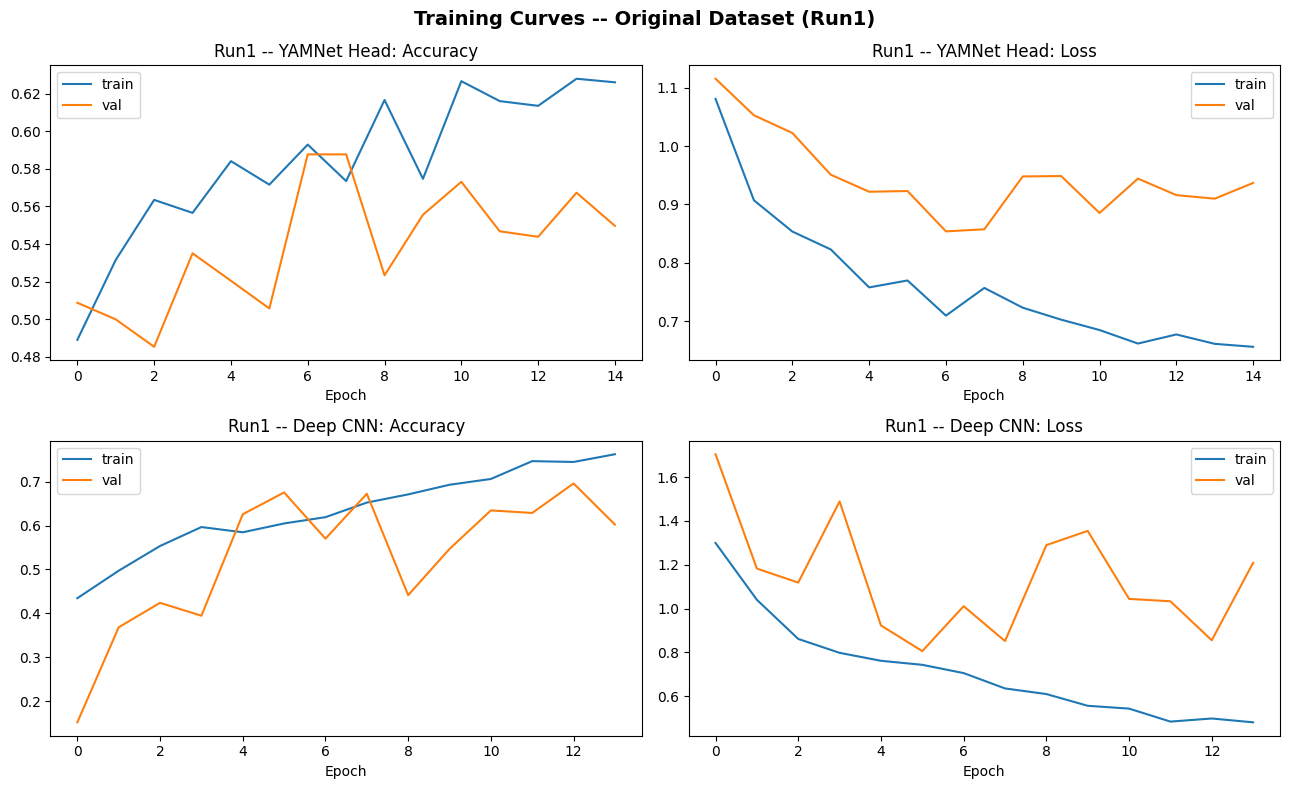

Saved: report_figures/03_training_curves_run1_original.png
Saved: report_figures/03_training_curves_run1_original.pdf


In [16]:
run1_yamnet_acc = [0.4891,0.5316,0.5635,0.5566,0.5841,0.5716,0.5929,0.5735,0.6166,0.5747,0.6266,0.6160,0.6135,0.6279,0.6260]
run1_yamnet_val_acc = [0.5088,0.5000,0.4854,0.5351,0.5205,0.5058,0.5877,0.5877,0.5234,0.5556,0.5731,0.5468,0.5439,0.5673,0.5497]
run1_yamnet_loss = [1.0811,0.9071,0.8535,0.8229,0.7577,0.7696,0.7093,0.7568,0.7229,0.7024,0.6846,0.6614,0.6770,0.6609,0.6558]
run1_yamnet_val_loss = [1.1156,1.0529,1.0226,0.9510,0.9218,0.9230,0.8538,0.8574,0.9480,0.9487,0.8854,0.9443,0.9160,0.9099,0.9369]

run1_cnn_acc = [0.4346,0.4972,0.5535,0.5966,0.5847,0.6048,0.6191,0.6523,0.6710,0.6929,0.7061,0.7467,0.7448,0.7624]
run1_cnn_val_acc = [0.1520,0.3684,0.4240,0.3947,0.6257,0.6754,0.5702,0.6725,0.4415,0.5468,0.6345,0.6287,0.6959,0.6023]
run1_cnn_loss = [1.2994,1.0402,0.8617,0.7984,0.7621,0.7437,0.7060,0.6360,0.6104,0.5569,0.5440,0.4848,0.4989,0.4815]
run1_cnn_val_loss = [1.7040,1.1825,1.1187,1.4890,0.9232,0.8062,1.0111,0.8519,1.2895,1.3544,1.0444,1.0334,0.8557,1.2090]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(run1_yamnet_acc, label='train'); axes[0,0].plot(run1_yamnet_val_acc, label='val')
axes[0,0].set_title('Run1 -- YAMNet Head: Accuracy'); axes[0,0].set_xlabel('Epoch'); axes[0,0].legend()
axes[0,1].plot(run1_yamnet_loss, label='train'); axes[0,1].plot(run1_yamnet_val_loss, label='val')
axes[0,1].set_title('Run1 -- YAMNet Head: Loss'); axes[0,1].set_xlabel('Epoch'); axes[0,1].legend()
axes[1,0].plot(run1_cnn_acc, label='train'); axes[1,0].plot(run1_cnn_val_acc, label='val')
axes[1,0].set_title('Run1 -- Deep CNN: Accuracy'); axes[1,0].set_xlabel('Epoch'); axes[1,0].legend()
axes[1,1].plot(run1_cnn_loss, label='train'); axes[1,1].plot(run1_cnn_val_loss, label='val')
axes[1,1].set_title('Run1 -- Deep CNN: Loss'); axes[1,1].set_xlabel('Epoch'); axes[1,1].legend()
fig.suptitle('Training Curves -- Original Dataset (Run1)', fontsize=14, fontweight='bold')
plt.tight_layout()
save_and_show(fig, "03_training_curves_run1_original")

## 9. Training curves -- chunkC (Re-chunked dataset, representative run)

Same principle: genuine historical epoch data for the exact verified
chunkC run.

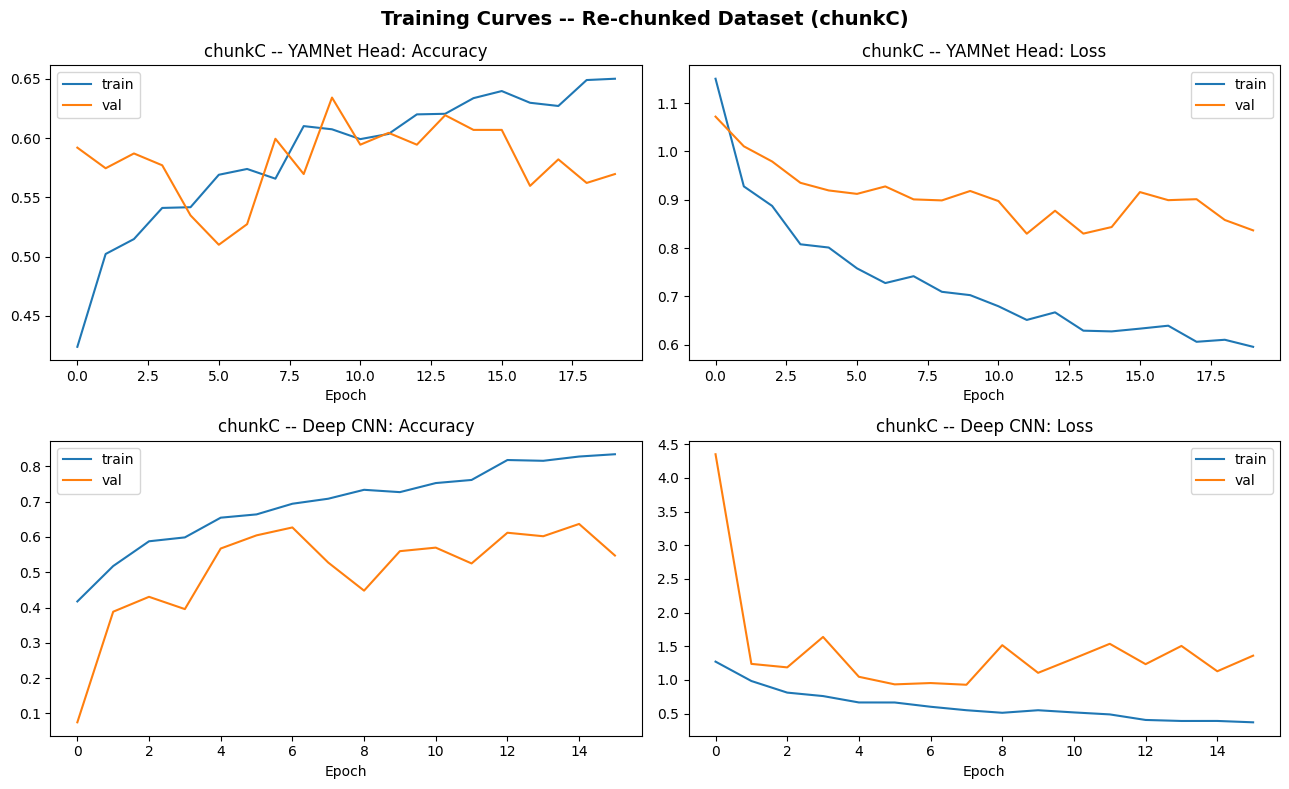

Saved: report_figures/04_training_curves_chunkC_rechunked.png
Saved: report_figures/04_training_curves_chunkC_rechunked.pdf


In [17]:
chunkC_yamnet_acc = [0.4238,0.5022,0.5148,0.5411,0.5417,0.5691,0.5740,0.5658,0.6102,0.6075,0.5992,0.6036,0.6201,0.6206,0.6338,0.6398,0.6299,0.6272,0.6491,0.6502]
chunkC_yamnet_val_acc = [0.5920,0.5746,0.5871,0.5771,0.5348,0.5100,0.5274,0.5995,0.5697,0.6343,0.5945,0.6045,0.5945,0.6194,0.6070,0.6070,0.5597,0.5821,0.5622,0.5697]
chunkC_yamnet_loss = [1.1504,0.9277,0.8873,0.8079,0.8012,0.7581,0.7277,0.7419,0.7096,0.7027,0.6797,0.6514,0.6671,0.6292,0.6277,0.6334,0.6395,0.6062,0.6104,0.5958]
chunkC_yamnet_val_loss = [1.0720,1.0106,0.9792,0.9351,0.9193,0.9122,0.9276,0.9008,0.8987,0.9182,0.8973,0.8298,0.8773,0.8300,0.8436,0.9159,0.8992,0.9012,0.8582,0.8367]

chunkC_cnn_acc = [0.4172,0.5175,0.5877,0.5987,0.6546,0.6639,0.6941,0.7083,0.7336,0.7270,0.7527,0.7615,0.8180,0.8158,0.8279,0.8344]
chunkC_cnn_val_acc = [0.0746,0.3881,0.4303,0.3955,0.5672,0.6045,0.6269,0.5274,0.4478,0.5597,0.5697,0.5249,0.6119,0.6020,0.6368,0.5473]
chunkC_cnn_loss = [1.2720,0.9841,0.8120,0.7606,0.6658,0.6653,0.6020,0.5505,0.5125,0.5503,0.5179,0.4884,0.4060,0.3909,0.3913,0.3709]
chunkC_cnn_val_loss = [4.3508,1.2383,1.1866,1.6384,1.0468,0.9343,0.9539,0.9285,1.5160,1.1055,1.3188,1.5366,1.2342,1.5048,1.1289,1.3605]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(chunkC_yamnet_acc, label='train'); axes[0,0].plot(chunkC_yamnet_val_acc, label='val')
axes[0,0].set_title('chunkC -- YAMNet Head: Accuracy'); axes[0,0].set_xlabel('Epoch'); axes[0,0].legend()
axes[0,1].plot(chunkC_yamnet_loss, label='train'); axes[0,1].plot(chunkC_yamnet_val_loss, label='val')
axes[0,1].set_title('chunkC -- YAMNet Head: Loss'); axes[0,1].set_xlabel('Epoch'); axes[0,1].legend()
axes[1,0].plot(chunkC_cnn_acc, label='train'); axes[1,0].plot(chunkC_cnn_val_acc, label='val')
axes[1,0].set_title('chunkC -- Deep CNN: Accuracy'); axes[1,0].set_xlabel('Epoch'); axes[1,0].legend()
axes[1,1].plot(chunkC_cnn_loss, label='train'); axes[1,1].plot(chunkC_cnn_val_loss, label='val')
axes[1,1].set_title('chunkC -- Deep CNN: Loss'); axes[1,1].set_xlabel('Epoch'); axes[1,1].legend()
fig.suptitle('Training Curves -- Re-chunked Dataset (chunkC)', fontsize=14, fontweight='bold')
plt.tight_layout()
save_and_show(fig, "04_training_curves_chunkC_rechunked")

## 10. Confusion matrices -- Run1 and chunkC, verified against your actual screenshots

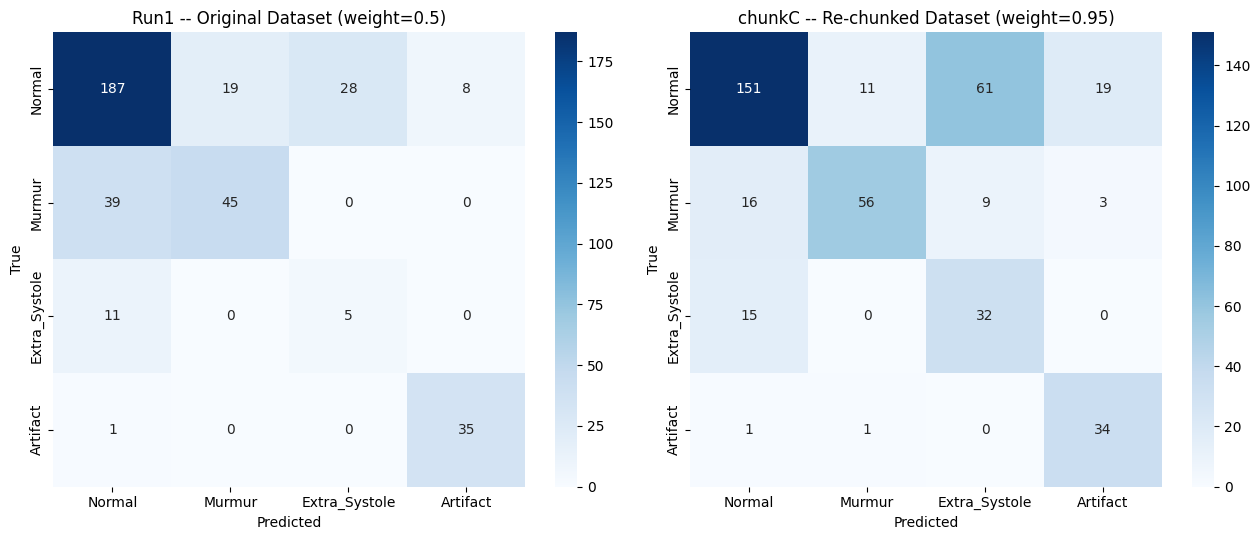

Saved: report_figures/05_confusion_matrices_run1_vs_chunkC.png
Saved: report_figures/05_confusion_matrices_run1_vs_chunkC.pdf


In [18]:
cm_run1 = np.array([
    [187, 19, 28, 8],
    [39, 45, 0, 0],
    [11, 0, 5, 0],
    [1, 0, 0, 35],
])
cm_chunkC = np.array([
    [151, 11, 61, 19],
    [16, 56, 9, 3],
    [15, 0, 32, 0],
    [1, 1, 0, 34],
])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sns.heatmap(cm_run1, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Run1 -- Original Dataset (weight=0.5)')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

sns.heatmap(cm_chunkC, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('chunkC -- Re-chunked Dataset (weight=0.95)')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')

plt.tight_layout()
save_and_show(fig, "05_confusion_matrices_run1_vs_chunkC")

## 11. Classification reports -- saved as text

In [19]:
report_run1 = """Dataset: Original -- Run1 (representative, weight=0.5 YAMNet/0.5 CNN)

              precision    recall  f1-score   support

      Normal       0.79      0.77      0.78       242
      Murmur       0.70      0.54      0.61        84
Extra_Systole      0.15      0.31      0.20        16
     Artifact      0.81      0.97      0.89        36

    accuracy                           0.72       378
   macro avg       0.61      0.65      0.62       378
weighted avg       0.74      0.72      0.73       378
"""

report_chunkC = """Dataset: Re-chunked -- chunkC (representative, weight=0.95 YAMNet/0.05 CNN)

              precision    recall  f1-score   support

      Normal       0.83      0.62      0.71       242
      Murmur       0.82      0.67      0.74        84
Extra_Systole      0.31      0.68      0.43        47
     Artifact      0.61      0.94      0.74        36

    accuracy                           0.67       409
   macro avg       0.64      0.73      0.65       409
weighted avg       0.75      0.67      0.69       409
"""

print(report_run1)
print(report_chunkC)

with open(os.path.join(FIGURES_DIR, "classification_report_run1_original.txt"), "w") as f:
    f.write(report_run1)
with open(os.path.join(FIGURES_DIR, "classification_report_chunkC_rechunked.txt"), "w") as f:
    f.write(report_chunkC)
print("Saved both classification report text files.")

Dataset: Original -- Run1 (representative, weight=0.5 YAMNet/0.5 CNN)

              precision    recall  f1-score   support

      Normal       0.79      0.77      0.78       242
      Murmur       0.70      0.54      0.61        84
Extra_Systole      0.15      0.31      0.20        16
     Artifact      0.81      0.97      0.89        36

    accuracy                           0.72       378
   macro avg       0.61      0.65      0.62       378
weighted avg       0.74      0.72      0.73       378

Dataset: Re-chunked -- chunkC (representative, weight=0.95 YAMNet/0.05 CNN)

              precision    recall  f1-score   support

      Normal       0.83      0.62      0.71       242
      Murmur       0.82      0.67      0.74        84
Extra_Systole      0.31      0.68      0.43        47
     Artifact      0.61      0.94      0.74        36

    accuracy                           0.67       409
   macro avg       0.64      0.73      0.65       409
weighted avg       0.75      0.67    

## 12. Dataset summary printout (for you and your supervisor)

In [20]:
print("=" * 55)
print(" DATASET SUMMARY")
print("=" * 55)
print(f"Dataset used for real-data sections: {DATASET_LABEL}")
print(f"Sample rate:        {TARGET_SR} Hz")
print(f"Spectrogram shape:  ({N_MELS}, {N_FRAMES})")
print(f"Classes:            {CLASSES}")
print()
counts = {}
for cls in CLASSES:
    class_dir = os.path.join(TRAIN_DIR, cls)
    counts[cls] = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
print(f"{'Class':<15}{'Train files':>12}")
for cls in CLASSES:
    print(f"{cls:<15}{counts[cls]:>12}")
print(f"\nTotal train files: {sum(counts.values())}")
print(f"Noise clips available: {len([f for f in os.listdir('noise_clips') if f.endswith('.wav')])}")
print("=" * 55)

 DATASET SUMMARY
Dataset used for real-data sections: rechunked_v3
Sample rate:        16000 Hz
Spectrogram shape:  (64, 188)
Classes:            ['Normal', 'Murmur', 'Extra_Systole', 'Artifact']

Class           Train files
Normal                  893
Murmur                  429
Extra_Systole           334
Artifact                168

Total train files: 1824
Noise clips available: 8


## 13. Your recorded ESP32 noise clips -- waveforms

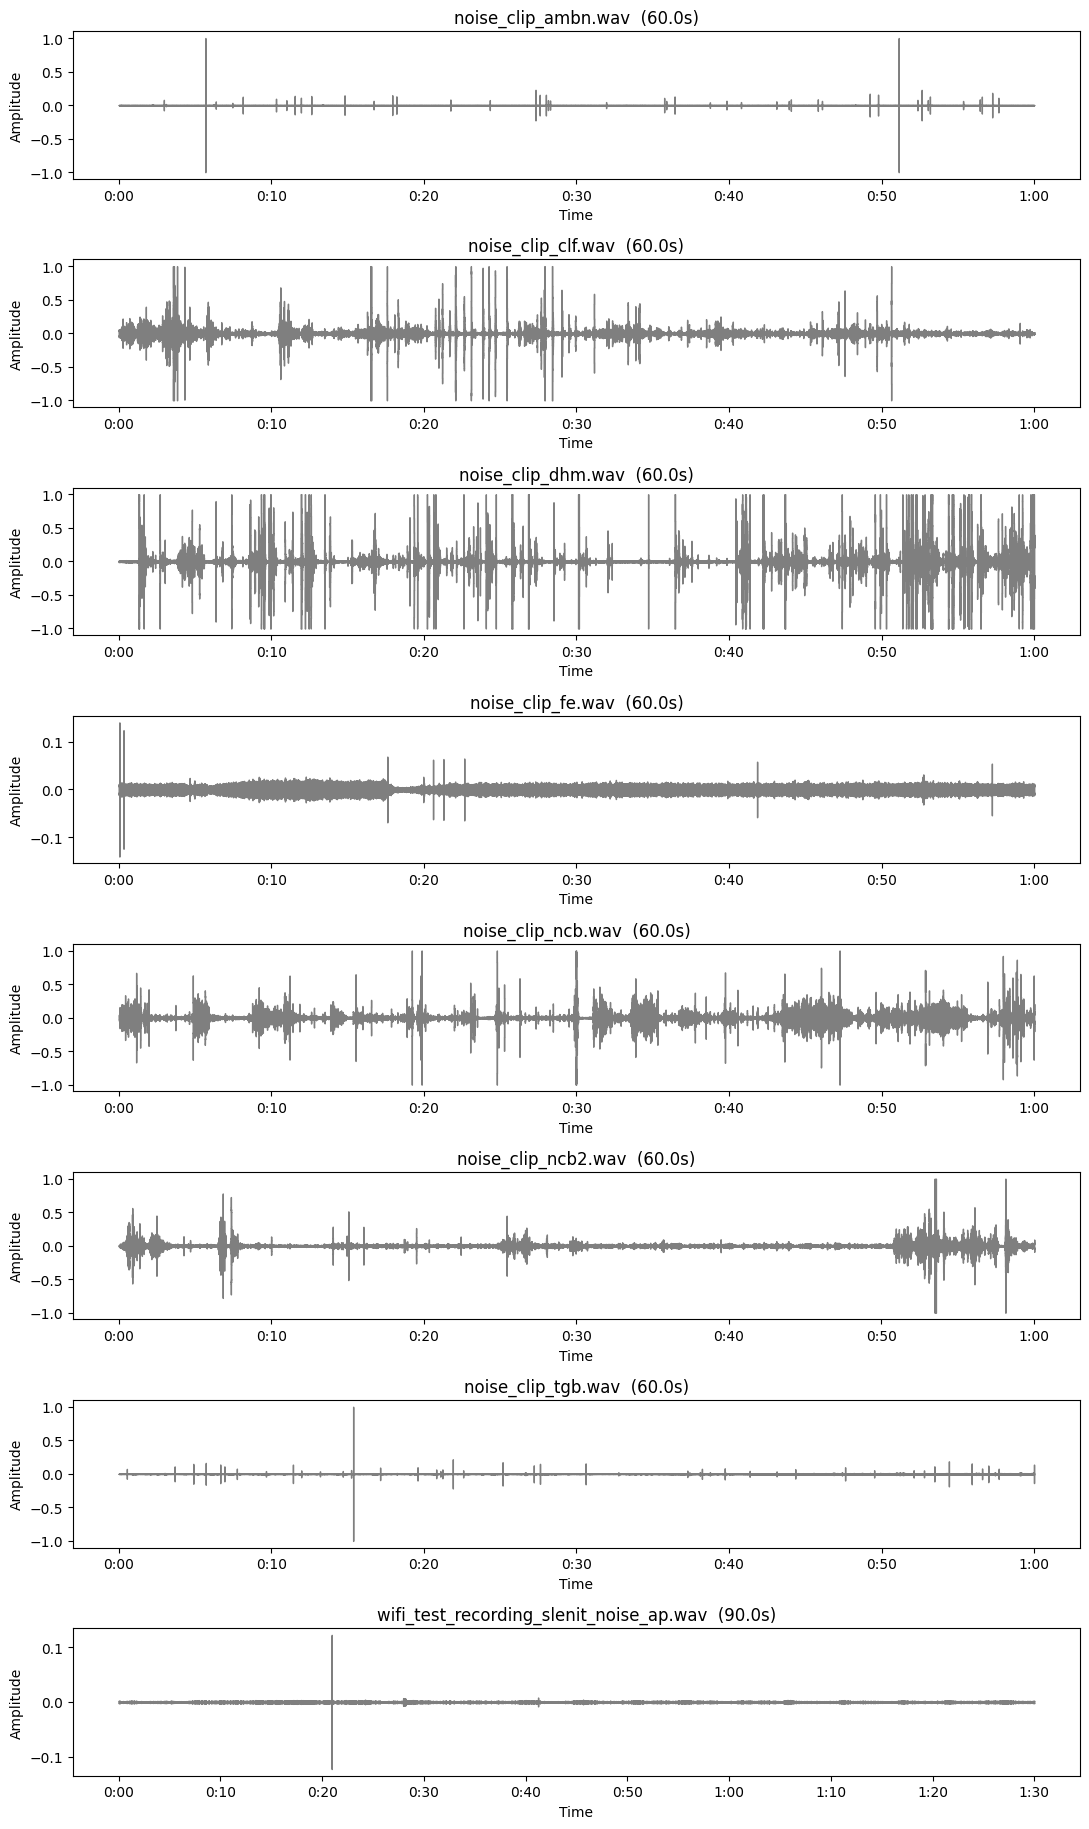

Saved: report_figures/09_noise_clips_waveforms.png
Saved: report_figures/09_noise_clips_waveforms.pdf


In [23]:
import librosa
noise_files = sorted(f for f in os.listdir("noise_clips") if f.endswith(".wav"))

fig, axes = plt.subplots(len(noise_files), 1, figsize=(11, 2.3 * len(noise_files)))
if len(noise_files) == 1:
    axes = [axes]

for i, fname in enumerate(noise_files):
    y_noise, sr = librosa.load(os.path.join("noise_clips", fname), sr=TARGET_SR)
    librosa.display.waveshow(y_noise, sr=sr, ax=axes[i], color='#7f7f7f')
    axes[i].set_title(f"{fname}  ({len(y_noise)/sr:.1f}s)")
    axes[i].set_ylabel("Amplitude")

plt.tight_layout()
save_and_show(fig, "09_noise_clips_waveforms")

## 14. A real training batch, visualized -- exactly what feeds the model

Batch tensor shape: (8, 64, 188, 1)


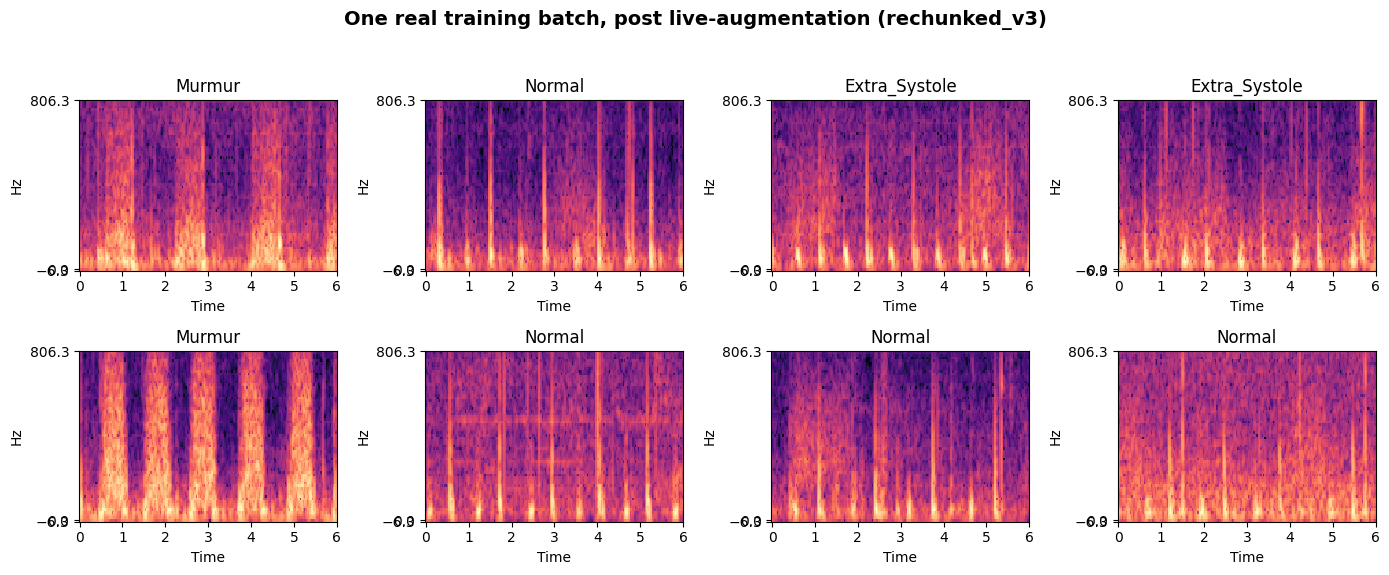

Saved: report_figures/10_real_training_batch.png
Saved: report_figures/10_real_training_batch.pdf


In [24]:
from train_data_generator import PCGSequence

batch_gen = PCGSequence(batch_size=8, augment=True)
X_show, y_show = batch_gen[0]
print("Batch tensor shape:", X_show.shape)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()
for i in range(8):
    librosa.display.specshow(X_show[i, :, :, 0], x_axis='time', y_axis='mel',
                             sr=TARGET_SR, fmax=FMAX, ax=axes[i], cmap='magma')
    axes[i].set_title(CLASSES[y_show[i]])
fig.suptitle(f"One real training batch, post live-augmentation ({DATASET_LABEL})", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
save_and_show(fig, "10_real_training_batch")

## 15. Band-pass filter effect on a real sample -- before vs. after

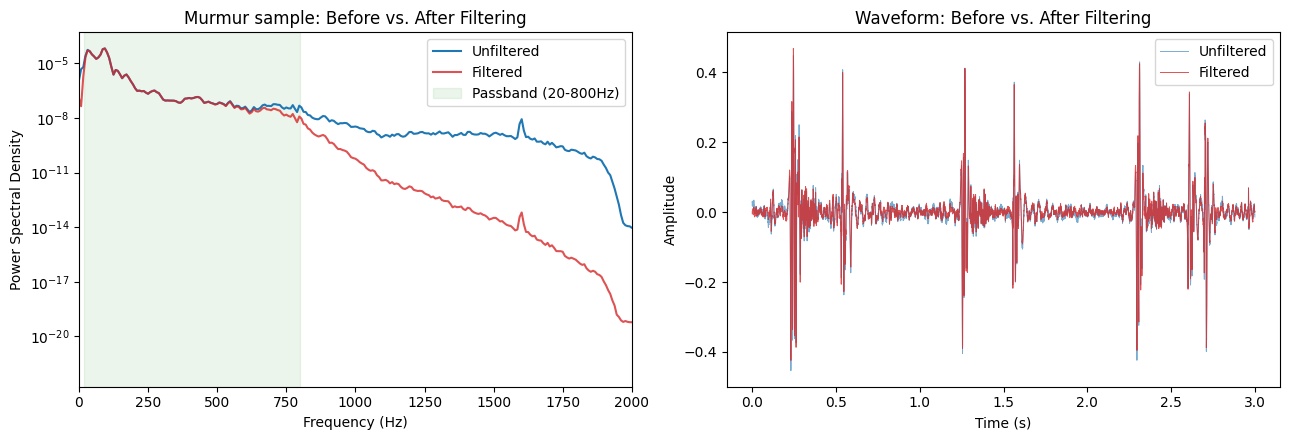

Saved: report_figures/11_bandpass_filter_real_sample_effect.png
Saved: report_figures/11_bandpass_filter_real_sample_effect.pdf
Fraction of signal power removed by filtering: 4.2%


In [25]:
sample_class = "Murmur"
sample_dir = os.path.join(TRAIN_DIR, sample_class)
sample_file = sorted(os.listdir(sample_dir))[0]
sample_path = os.path.join(sample_dir, sample_file)

from spectrogram_utils import apply_bandpass
from scipy.signal import welch

y_unfiltered, _ = librosa.load(sample_path, sr=TARGET_SR)
y_filtered = apply_bandpass(y_unfiltered, TARGET_SR)

freqs_u, psd_u = welch(y_unfiltered, fs=TARGET_SR, nperseg=2048)
freqs_f, psd_f = welch(y_filtered, fs=TARGET_SR, nperseg=2048)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogy(freqs_u, psd_u, color='#1f77b4', label='Unfiltered')
axes[0].semilogy(freqs_f, psd_f, color='#d62728', label='Filtered', alpha=0.8)
axes[0].axvspan(20, 800, color='green', alpha=0.08, label='Passband (20-800Hz)')
axes[0].set_xlim(0, 2000)
axes[0].set_xlabel('Frequency (Hz)'); axes[0].set_ylabel('Power Spectral Density')
axes[0].set_title(f'{sample_class} sample: Before vs. After Filtering')
axes[0].legend()

t = np.arange(len(y_unfiltered)) / TARGET_SR
axes[1].plot(t, y_unfiltered, color='#1f77b4', alpha=0.6, label='Unfiltered', linewidth=0.7)
axes[1].plot(t, y_filtered, color='#d62728', alpha=0.8, label='Filtered', linewidth=0.7)
axes[1].set_xlabel('Time (s)'); axes[1].set_ylabel('Amplitude')
axes[1].set_title('Waveform: Before vs. After Filtering')
axes[1].legend()

plt.tight_layout()
save_and_show(fig, "11_bandpass_filter_real_sample_effect")

power_removed = 1 - (np.sum(psd_f) / np.sum(psd_u))
print(f"Fraction of signal power removed by filtering: {power_removed*100:.1f}%")

## 16. Copy everything to Drive

In [26]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
DRIVE_FOLDER = "/content/drive/MyDrive/heart_project_visuals"
os.makedirs(DRIVE_FOLDER, exist_ok=True)

drive_figures_dir = os.path.join(DRIVE_FOLDER, f"report_figures_{DATASET_LABEL}")
if os.path.exists(drive_figures_dir):
    shutil.rmtree(drive_figures_dir)
shutil.copytree(FIGURES_DIR, drive_figures_dir)

print("Copied all figures (PNG + PDF) and reports to:", drive_figures_dir)
print("Contents:", os.listdir(drive_figures_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied all figures (PNG + PDF) and reports to: /content/drive/MyDrive/heart_project_visuals/report_figures_rechunked_v3
Contents: ['11_bandpass_filter_real_sample_effect.pdf', 'classification_report_run1_original.txt', '05_confusion_matrices_run1_vs_chunkC.pdf', '10_real_training_batch.png', '03_training_curves_run1_original.png', '11_bandpass_filter_real_sample_effect.png', '09_noise_clips_waveforms.png', '01_class_distribution_both_datasets.pdf', '04_training_curves_chunkC_rechunked.png', '04_training_curves_chunkC_rechunked.pdf', '03_training_curves_run1_original.pdf', '02_bandpass_filter_response.pdf', '09_noise_clips_waveforms.pdf', '05_confusion_matrices_run1_vs_chunkC.png', '01_class_distribution_both_datasets.png', '02_bandpass_filter_response.png', '10_real_training_batch.pdf', 'classification_report_chunkC_rechunked.txt']
